In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

J = 1.0
kB = 1.0
L = 16

eq_steps = 500
mc_steps = 2000
block_size = 100


def make_lattice(shape, ordered=False):
    if ordered:
        return np.ones(shape, dtype=np.int8)
    return rng.choice([-1, 1], size=shape).astype(np.int8)


def total_energy(lattice, h=0.0):
    # По одному направлению вдоль каждой оси:
    # каждая связь учитывается ровно один раз.
    bonds = sum(
        np.sum(lattice * np.roll(lattice, -1, axis=axis))
        for axis in range(lattice.ndim)
    )
    return -J * bonds - h * np.sum(lattice)


def delta_energy(lattice, i, h=0.0):
    # i — плоский индекс случайно выбранного спина.
    if lattice.ndim == 1:
        n = lattice.size
        spin = lattice[i]
        neighbors = lattice[(i - 1) % n] + lattice[(i + 1) % n]
    else:
        rows, cols = lattice.shape
        r, c = divmod(i, cols)
        spin = lattice[r, c]
        neighbors = (
            lattice[(r - 1) % rows, c]
            + lattice[(r + 1) % rows, c]
            + lattice[r, (c - 1) % cols]
            + lattice[r, (c + 1) % cols]
        )

    return 2.0 * spin * (J * neighbors + h)


def metropolis_sweep(lattice, T, h=0.0):
    # N попыток, узлы выбираются с возвращением.
    for i in rng.integers(lattice.size, size=lattice.size):
        dE = delta_energy(lattice, i, h)

        if dE <= 0 or (
            T > 0 and rng.random() < np.exp(-dE / (kB * T))
        ):
            lattice.flat[i] *= -1


def simulate(lattice, T, eq_steps, mc_steps, h=0.0):
    """Возвращает всю историю, включая прогрев."""
    energies = np.empty(eq_steps + mc_steps)
    magnetizations = np.empty(eq_steps + mc_steps)

    for step in range(eq_steps + mc_steps):
        metropolis_sweep(lattice, T, h)
        energies[step] = total_energy(lattice, h) / lattice.size
        magnetizations[step] = np.mean(lattice)

    return energies, magnetizations


def mean_error(values, block_size=block_size):
    """Ошибка среднего по блокам последовательных измерений."""
    n_blocks = len(values) // block_size
    if n_blocks < 2:
        raise ValueError("Нужно хотя бы два блока измерений")

    blocks = values[:n_blocks * block_size].reshape(
        n_blocks, block_size
    ).mean(axis=1)

    return np.mean(values), np.std(blocks, ddof=1) / np.sqrt(n_blocks)


# Проверка локального изменения энергии для обеих геометрий.
for shape in ((16,), (4, 4)):
    spins = make_lattice(shape)
    before = total_energy(spins, h=0.2)
    dE = delta_energy(spins, 3, h=0.2)
    spins.flat[3] *= -1
    assert np.isclose(total_energy(spins, h=0.2) - before, dE)

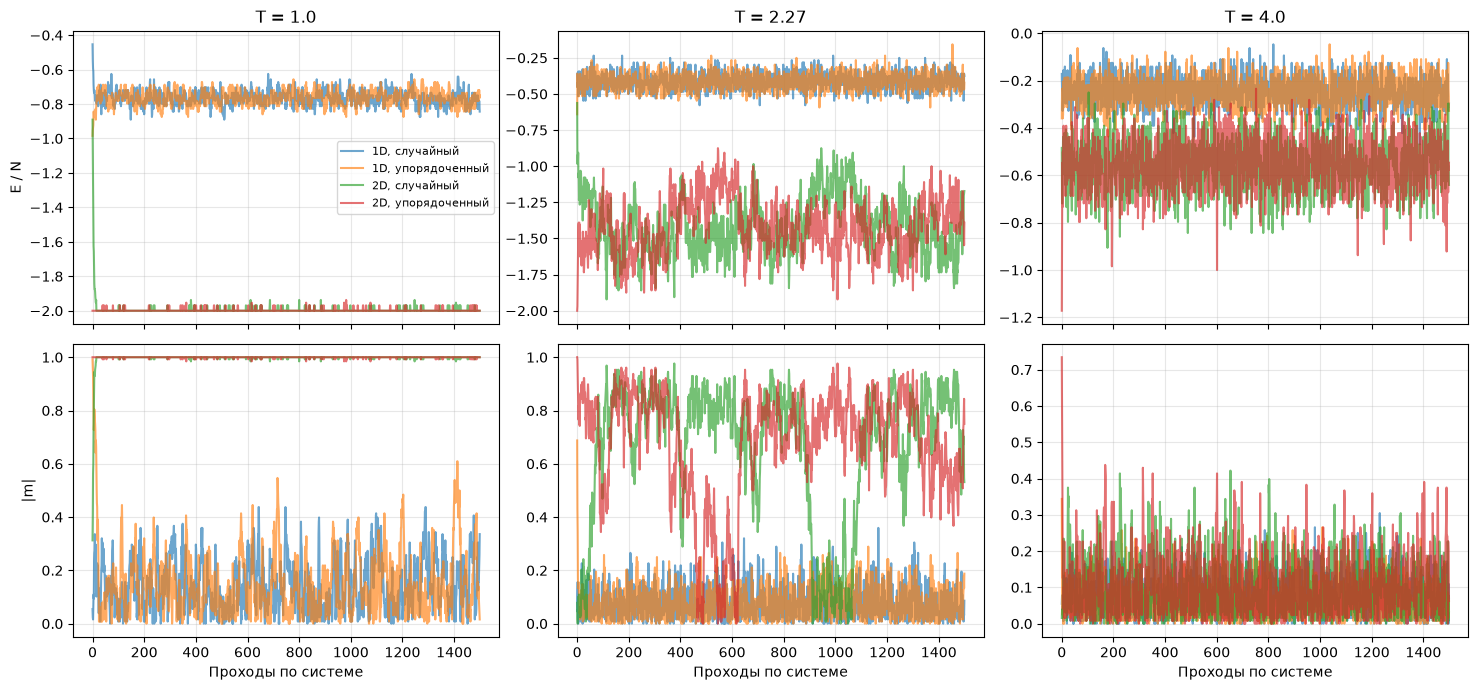

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)

for column, T in enumerate((1.0, 2.27, 4.0)):
    for shape, name in (
        ((L * L,), "1D"),
        ((L, L), "2D"),
    ):
        for ordered, start in (
            (False, "случайный"),
            (True, "упорядоченный"),
        ):
            e, m = simulate(
                make_lattice(shape, ordered),
                T,
                eq_steps=0,
                mc_steps=1500,
            )

            label = f"{name}, {start}"
            axes[0, column].plot(e, alpha=0.65, label=label)
            axes[1, column].plot(np.abs(m), alpha=0.65)

        axes[0, column].set_title(f"T = {T}")
        axes[1, column].set_xlabel("Проходы по системе")

axes[0, 0].set_ylabel("E / N")
axes[1, 0].set_ylabel("|m|")
axes[0, 0].legend(fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

L = 16: расчёт 27 температур
L = 16: максимум теплоёмкости при T ≈ 0.800
L = 24: расчёт 27 температур
L = 24: максимум теплоёмкости при T ≈ 0.800


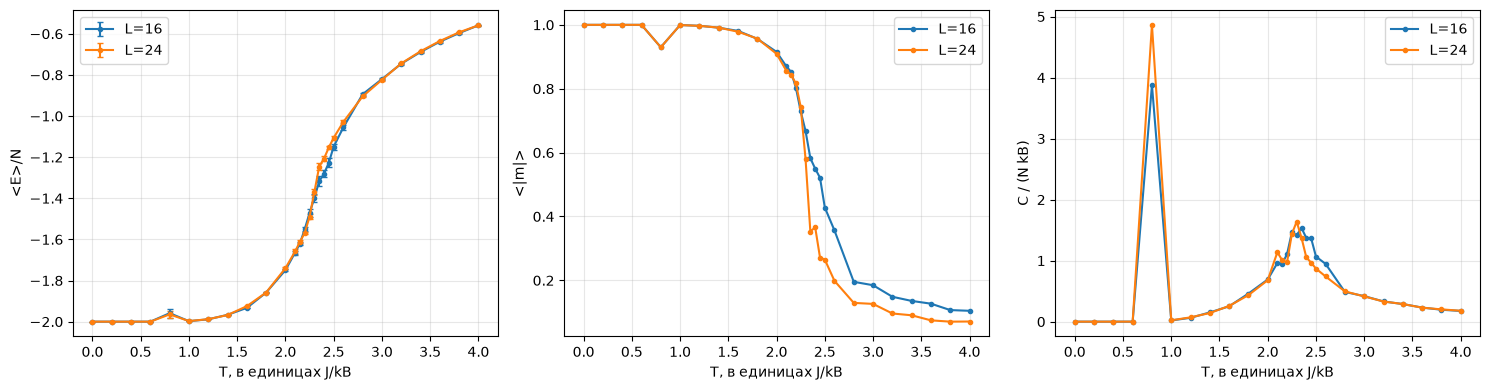

In [6]:
sizes = (16, 24)

# Грубая сетка во всём диапазоне и более частая около перехода.
temperatures = np.unique(np.round(np.r_[
    np.arange(0.2, 4.01, 0.2),
    np.arange(2.10, 2.51, 0.05),
], 3))

results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for side in sizes:
    print(f"L = {side}: расчёт {len(temperatures)} температур")
    N = side * side

    # Столбцы: T, средняя энергия, ошибка энергии, <|m|>, c.
    # T=0 задаём по основному состоянию.
    rows = [[0.0, -2 * J, 0.0, 1.0, 0.0]]

    for T in temperatures:
        e, m = simulate(
            make_lattice((side, side)),
            T,
            eq_steps,
            mc_steps,
        )

        # В статистику входит только участок после прогрева.
        e = e[eq_steps:]
        m = m[eq_steps:]

        mean_e, error_e = mean_error(e)
        mean_abs_m = np.mean(np.abs(m))

        # Безразмерная теплоёмкость C / (N kB).
        c = N * np.var(e) / (kB * T) ** 2

        rows.append([T, mean_e, error_e, mean_abs_m, c])

    data = np.array(rows)
    results[side] = data

    peak = np.argmax(data[:, 4])
    print(f"L = {side}: максимум теплоёмкости при T ≈ {data[peak, 0]:.3f}")

    axes[0].errorbar(
        data[:, 0], data[:, 1], yerr=data[:, 2],
        fmt="o-", markersize=3, capsize=2, label=f"L={side}",
    )
    axes[1].plot(
        data[:, 0], data[:, 3], "o-", markersize=3, label=f"L={side}",
    )
    axes[2].plot(
        data[:, 0], data[:, 4], "o-", markersize=3, label=f"L={side}",
    )

for ax, ylabel in zip(axes, ("<E>/N", "<|m|>", "C / (N kB)")):
    ax.set_xlabel("T, в единицах J/kB")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

h=0.02: Θ_CW ≈ 2.430, χ²/ν ≈ 0.57
h=0.04: Θ_CW ≈ 2.504, χ²/ν ≈ 0.46


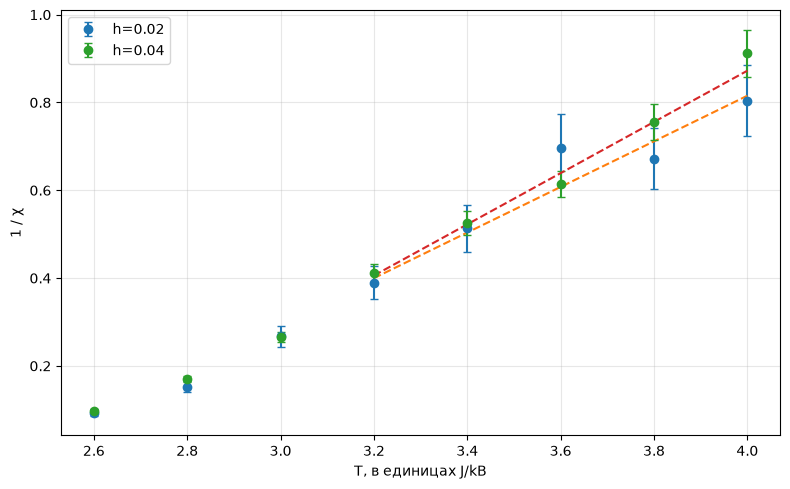

In [7]:
field_temperatures = np.round(np.arange(2.6, 4.01, 0.2), 2)
field_values = (0.02, 0.04)

fig, ax = plt.subplots(figsize=(8, 5))

for h in field_values:
    chi_values = []
    chi_errors = []

    for T in field_temperatures:
        estimates = []

        for sign in (1, -1):
            _, m = simulate(
                make_lattice((L, L)),
                T,
                eq_steps,
                5 * mc_steps,
                h=sign * h,
            )
            estimates.append(mean_error(m[eq_steps:]))

        (m_plus, error_plus), (m_minus, error_minus) = estimates

        chi_values.append((m_plus - m_minus) / (2 * h))
        chi_errors.append(
            np.hypot(error_plus, error_minus) / (2 * h)
        )

    chi = np.array(chi_values)
    error_chi = np.array(chi_errors)

    # Не подгоняем плохо измеренный отклик.
    if np.any(chi <= 0) or np.any(chi <= 2 * error_chi):
        print(
            f"h={h}: восприимчивость определена недостаточно точно; "
            "увеличьте число измерений."
        )
        continue

    inverse_chi = 1 / chi
    error_inverse = error_chi / chi**2

    ax.errorbar(
        field_temperatures, inverse_chi,
        yerr=error_inverse, fmt="o", capsize=3, label=f"h={h}",
    )

    # Проверяем высокотемпературную часть.
    fit = field_temperatures >= 3.2
    x = field_temperatures[fit]
    y = inverse_chi[fit]
    error_y = error_inverse[fit]

    a, b = np.polyfit(x, y, deg=1, w=1 / error_y)
    prediction = a * x + b

    theta_cw = -b / a
    reduced_chi2 = np.sum(
        ((y - prediction) / error_y) ** 2
    ) / (len(x) - 2)

    print(
        f"h={h}: Θ_CW ≈ {theta_cw:.3f}, "
        f"χ²/ν ≈ {reduced_chi2:.2f}"
    )
    ax.plot(x, prediction, "--")

ax.set_xlabel("T, в единицах J/kB")
ax.set_ylabel("1 / χ")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

1. Сделали 4 соседа вместо двух. При одинаковом числе спинов энергия в 2D оказалась ниже. Например, при $T=1$ для цепочки получилось примерно $E/N\approx-0.76$, а для квадратной решётки — около $-2$. Это связано с увеличением числа взаимодействующих пар. В основном состоянии энергия на спин равна $-J$ для цепочки и $-2J$ для квадратной решётки.

   Время установления равновесия также зависит от размерности и температуры. На графиках при $T\approx2.27$ в двумерной системе видны длительные колебания энергии и намагниченности, тогда как вдали от этой области стационарное поведение устанавливается быстрее

2. Получили зависимость энергии от температуры для решёток $16\times16$ и $24\times24$. В целом есть рост энергии на спин от $-2$ при $T=0$ до примерно $-0.56$ при $T=4$. Точка при нулевой температуре задана по основному состоянию, остальные получены моделированием

3. Полученные зависимости в области $T\approx2.3$ согласуются с непрерывным фазовым переходом второго рода. На графике энергии нет заметного скачка, но меняется её наклон. Переход отчётливее виден по резкому уменьшению $\langle|m|\rangle$ и пику теплоёмкости. Из-за конечного размера решёток эти особенности сглажены, а выше перехода средний модуль намагниченности остаётся небольшим положительным числом

   При этом в расчётах есть аномальная точка $T=0.8$: одновременно наблюдаются выброс энергии, провал $\langle|m|\rangle$ и сильный пик теплоёмкости. Это похоже на ошибку или следствие случайной генерации начальных спинов

   По отдельному пику теплоёмкости около $2.3$ и спаду намагниченности в области $2.2$–$2.4$ я получаю грубую оценку $T_c\approx2.3\,J/k_B$. Она близка к теоретическому значению $T_c\approx2.269\,J/k_B$ для квадратной решётки

4. После добавления поля я определил восприимчивость по разности средних намагниченностей при противоположных полях и построил $1/\chi(T)$. На участке $3.2\leq T\leq4$ линейная зависимость согласуется с точками в пределах показанных погрешностей. Для $h=0.02$ подгонка дала $\Theta_{\mathrm{CW}}\approx2.430$ и $\chi^2/\nu\approx0.57$, а для $h=0.04$ — $\Theta_{\mathrm{CW}}\approx2.504$ и $\chi^2/\nu\approx0.46$.

   Поэтому в этом температурном интервале зависимость допускает приближённое описание законом Кюри—Вейсса $\chi=C/(T-\Theta_{\mathrm{CW}})$. Экстраполяция даёт температурный параметр около $2.4$–$2.5\,J/k_B$